Bu notebook'ta anomaliyi Z-Score yöntemi ile tespit etmeye çalışacağız.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
print(Path.cwd())

c:\Users\asus\Desktop\kpi-anomaly-detective


In [2]:
## öncelikle csv dosyasını okuyalım.
import pandas as pd # pandas kütüphanesini içe aktarıyoruz.
import yaml

with open("configs/config.yaml", "r") as f:
    config = yaml.safe_load(f)

data = pd.read_csv(filepath_or_buffer = config['paths']['input_csv'] ,parse_dates = ['order_purchase_timestamp'])
# • parse_dates=['sütun_adı'] parametresi, Pandas'a "Bu CSV'yi okurken bu sütundaki verileri düz yazı (string) olarak bırakma, okurken otomatik olarak datetime nesnesine çevir" talimatı verir. Böylece her seferinde pd.to_datetime kodunu tekrar tekrar yazmak zorunda kalmayız.

In [3]:
data.head() # verimize genel bir bakış atalım.

,order_purchase_timestamp,price
0,2017-01-11,2611.26
1,2017-01-12,2234.58
2,2017-01-13,2505.58
3,2017-01-14,1112.69
4,2017-01-15,2199.57


In [4]:
# bu blokta her bir güne ait gelirin z-skorlarını hesaplayacağız.
# Z-Skor Formülü: (X - μ) / σ
gunluk_gelir_ortalama = data['price'].mean() 
gunluk_gelir_sapma = data['price'].std()
data['z-score'] = (data['price'] - gunluk_gelir_ortalama) / gunluk_gelir_sapma

In [5]:
# Şimdide yeni oluşturulan sütuna göz atıyoruz.
data["z-score"].head(10)

0   -1.648578
1   -1.679437
2   -1.657236
3   -1.771347
4   -1.682305
5   -1.591505
6   -1.591947
7   -1.532156
8   -1.571349
9   -1.531872
Name: z-score, dtype: float64

### Anomali sınırı belirleme
Anomali tespitinde kullanılan Z-Skor yöntemi, verilerin normal dağıldığı durumda kullanılan bir yöntemdir. Öncelikle aşağıda verilerin normal dağılıp dağılmadığını tespit edeceğiz.

In [6]:
# H0: Veriler normal dağılıma sahiptir.
# H1: Veriler normal dağılıma sahip değildir.

# normallik testi için Shapiro-Wilk testini kullanacağız.
from scipy.stats import shapiro
statistic, p_value = shapiro(data['price'])

if p_value < 0.05:
    print("Price sütunu normal dağılıma uymamaktadır.")
else:
    print("Price sütunu normal dağılıma uymaktadır.")
print(f"Shapiro-Wilk Testi İstatistiği: {statistic}, p-değeri: {p_value}")

Price sütunu normal dağılıma uymamaktadır.
Shapiro-Wilk Testi İstatistiği: 0.8815909431794534, p-değeri: 8.812676601027154e-21


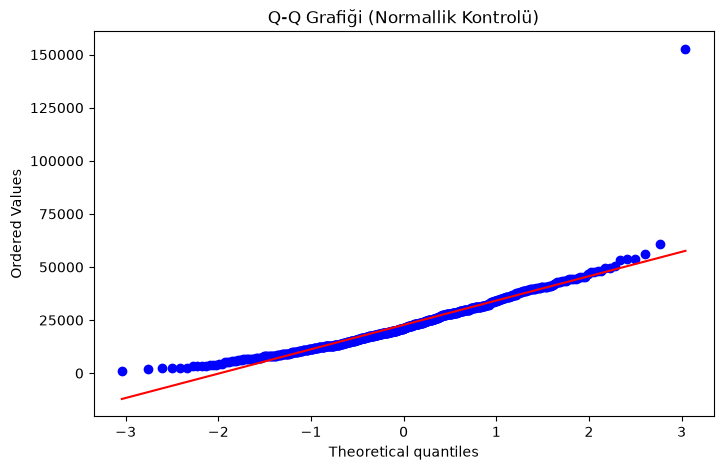

In [7]:
# şimdide normalliği kontrolü için Q-Q grafiğini çizelim.

import scipy.stats as stats
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
stats.probplot(data['price'], dist="norm", plot=plt)
plt.title("Q-Q Grafiği (Normallik Kontrolü)")
plt.show()

### Shapiro-Wilk ve Görsel Q-Q Plot Normallik testi sonuçları

Shapiro-Wilk testi sonucunda elde edilen p-value 10 üzeri -20 değeri, verinin normal dağılıma uymadığına dair çok güçlü bir kanıt sunmaktadır. Q-Q plot grafiği incelendiğinde, verinin orta kısmı normal dağılım çizgisine yakın gözükse bile, verideki her iki kuyruğun da normal dağılım çizgisinden saptığı açıkça görülmektedir. 

In [8]:
## Veri biliminde normal dağılım varsayımı altında;
# Verilerin %68'i -1 ile +1 Z-Score sınırları arasında kalır.
# Verilerin %95'i -2 ile +2 Z-Score sınırları arasında kalır.
# Verilerin %99.7'si -3 ile +3 Z-Score sınırları arasında kalır.

# Sonuç olarak, mutlak değer olarak 3'ten büyük Z-Score değerleri, anomali olarak kabul edilebilir. Bu nedenle, threshold (eşik değerini) 3 olarak belirliyoruz.

# Burada threshold değerini config.yaml dosyasından alıyoruz. Önceki notebook'ta da tarihleri config.yaml dosyasından almıştık. Bu sayede, kodu değiştirmeden sadece config.yaml dosyasını değiştirerek farklı threshold değerleri ile çalışabiliriz.

threshold = config['detection']['z_threshold']

# Anomali olan gözlemleri filtreleyelim.
anomalies = data[abs(data['z-score']) > threshold]
print(f"Anomali olarak tespit edilen gözlem sayısı: {len(anomalies)}")
print(anomalies)

Anomali olarak tespit edilen gözlem sayısı: 2
    order_purchase_timestamp      price    z-score
317               2017-11-24  152653.74  10.643505
318               2017-11-25   60923.48   3.128593


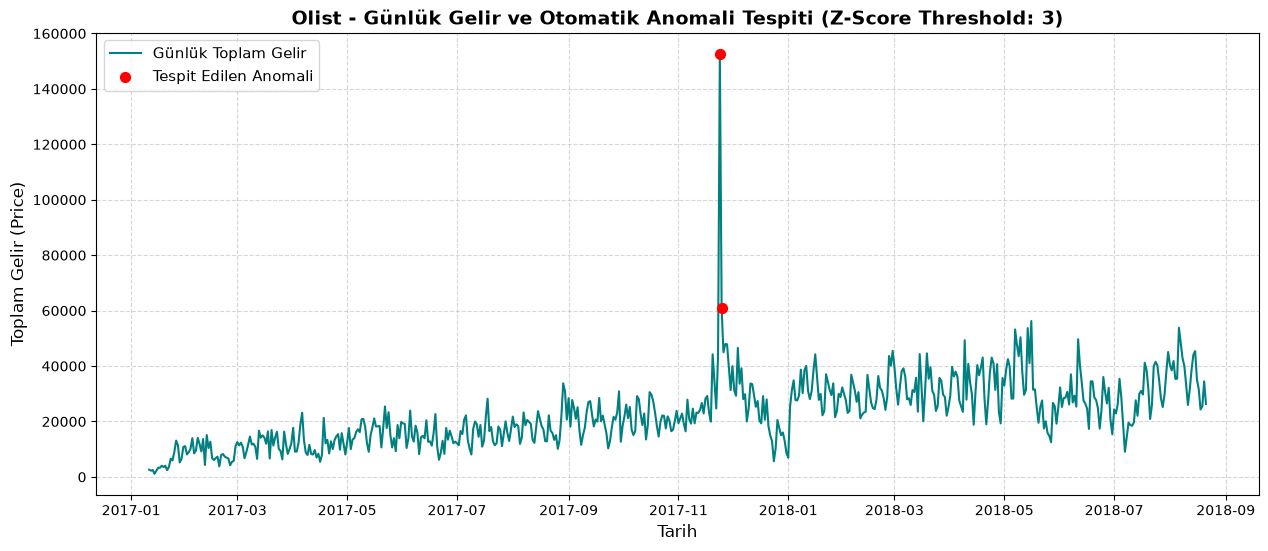

In [9]:

# 1. Grafiğin boyutunu ve arka plan kalitesini ayarlıyoruz
plt.figure(figsize=(15, 6))

# 2. Tüm günlük gelir serisini düz çizgi (line plot) olarak çizdiriyoruz
plt.plot(
    data['order_purchase_timestamp'], 
    data['price'], 
    color='teal', 
    linewidth=1.5, 
    label='Günlük Toplam Gelir'
)

# 3. Sadece anomali olan günleri kırmızı noktalar (scatter) şeklinde üzerine konduruyoruz
plt.scatter(
    anomalies['order_purchase_timestamp'], 
    anomalies['price'], 
    color='red', 
    s=50,                  # Noktaların büyüklüğü
    marker='o',            # Nokta şekli (yuvarlak)
    label='Tespit Edilen Anomali', 
    zorder = 5            # Noktaların çizginin üstünde görünmesini garantiler
)

# 4. Grafik süslemeleri ve okunabilirlik ayarları

plt.title(f'Olist - Günlük Gelir ve Otomatik Anomali Tespiti (Z-Score Threshold: {threshold})', fontsize=14, fontweight='bold')
plt.xlabel('Tarih', fontsize=12)
plt.ylabel('Toplam Gelir (Price)', fontsize=12)

# Arkaya hafif kılavuz çizgileri ekleyelim
plt.grid(True, linestyle='--', alpha=0.5)

# Sol üst köşeye hangi rengin ne anlama geldiğini gösteren kutucuğu ekleyelim
plt.legend(loc='upper left', fontsize=11)

# Grafiği ekrana basalım
plt.show()


### Faz 1: Sabit (Global) Z-Score Modelinin Sonuç Raporu ve Sınırları

Yapılan analizler sonucunda, tüm veri setinin genel ortalamasına dayanan Sabit Z-Score modelinin durağan olmayan (büyüyen/trend içeren) e-ticaret verilerinde çöktüğü matematiksel olarak ispatlanmıştır. 

**Matematiksel Kanıt (Ocak 2017 Tuzağı):**
Ocak 2017'deki sıradan günlerin genel ortalamaya göre Z-Skorları negatif ve $-1.5$ ile $-1.7$ bandında yüksek çıkmaktadır. Eğer Ocak 2017'de operasyonel bir kriz yaşansaydı ve günlük gelir 2.600 TL'den 1.300 TL'ye (yarı yarıya) düşseydi, o günün Z-Skoru yaklaşık **$-1.76$** olarak hesaplanacaktı. Sistem sadece $\pm3$ sınırının dışını aradığı için, gelirdeki bu %50'lik devasa çöküşü "normal bir gün" sayacak ve **hiçbir şekilde yakalayamayacaktı**.

Bu durum, global Z-Score modelinin geçmiş dönemlerdeki krizlere karşı tamamen kör olduğunu kanıtlamaktadır. Çözüm olarak sistemin trende uyum sağlamasını sağlayacak **Hareketli (Rolling) Z-Score** yöntemine geçilmiştir.

In [10]:
pencere_boyutu = config['detection']['rolling_window']

print(f"Eşik değer: {threshold}, Pencere Boyutu: {pencere_boyutu}")

Eşik değer: 3, Pencere Boyutu: 28


In [11]:
kaydirilmis_gelir = data['price'].shift(1)
kaydirilmis_gelir.head(10)

# Black Friday gibi anomali günlerinin kendi ortalamasını şişirip kendini gizlemesini engellemek ve geleceğe bakma hatası (leakage) yapmamak için gelir sütununu (price) önce 1 gün aşağı kaydırıyoruz.

0        NaN
1    2611.26
2    2234.58
3    2505.58
4    1112.69
5    2199.57
6    3307.92
7    3302.53
8    4032.36
9    3553.95
Name: price, dtype: float64

In [12]:
# Şimdi bu kaydırılmış veri üzerinden, bilgisayara her gün için geriye dönük 28 günlük ortalamayı ve standart sapmayı hesaplatıp ana tablomuza yeni sütunlar olarak ekliyoruz:

# Her gün için geriye dönük 28 günün ortalamasını bulur
data['rolling_mean'] = kaydirilmis_gelir.rolling(window=pencere_boyutu).mean()

# Her gün için geriye dönük 28 günün standart sapmasını bulur
data['rolling_std'] = kaydirilmis_gelir.rolling(window=pencere_boyutu).std()

data.head(30)

,order_purchase_timestamp,price,z-score,rolling_mean,rolling_std
0,2017-01-11,2611.26,-1.648578,NaN,NaN
1,2017-01-12,2234.58,-1.679437,NaN,NaN
2,2017-01-13,2505.58,-1.657236,NaN,NaN
3,2017-01-14,1112.69,-1.771347,NaN,NaN
4,2017-01-15,2199.57,-1.682305,NaN,NaN
5,2017-01-16,3307.92,-1.591505,NaN,NaN
6,2017-01-17,3302.53,-1.591947,NaN,NaN
7,2017-01-18,4032.36,-1.532156,NaN,NaN
8,2017-01-19,3553.95,-1.571349,NaN,NaN
9,2017-01-20,4035.83,-1.531872,NaN,NaN


In [13]:
# Dinamik ortalama ve sapmalarımız hazır olduğuna göre, artık her günün kendi Z-Skorunu bulabiliriz.

# Dinamik Z-Score formülünü uyguluyoruz
data['rolling_z_score'] = (data['price'] - data['rolling_mean']) / data['rolling_std']

data['rolling_z_score'].head(30)

0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
5          NaN
6          NaN
7          NaN
8          NaN
9          NaN
10         NaN
11         NaN
12         NaN
13         NaN
14         NaN
15         NaN
16         NaN
17         NaN
18         NaN
19         NaN
20         NaN
21         NaN
22         NaN
23         NaN
24         NaN
25         NaN
26         NaN
27         NaN
28    1.309219
29    0.536518
Name: rolling_z_score, dtype: float64

In [14]:
anomalies_rolling = data[abs(data['rolling_z_score']) > threshold]
print(f"28 günlük kaydırma sonucu anomali olarak tespit edilen gözlem sayısı: {len(anomalies_rolling)}")
print(anomalies_rolling)

28 günlük kaydırma sonucu anomali olarak tespit edilen gözlem sayısı: 7
    order_purchase_timestamp      price    z-score  rolling_mean  rolling_std  \
85                2017-04-06   23168.89   0.035586  12374.364643  3549.108654   
188               2017-07-18   28238.20   0.450884  14270.811071  4301.000785   
230               2017-08-29   33756.48   0.902963  17248.629643  3821.955540   
313               2017-11-20   44235.47   1.761444  21898.825357  3420.922228   
316               2017-11-23   43563.89   1.706426  23378.370000  5752.695822   
317               2017-11-24  152653.74  10.643505  24153.801786  6890.179017   
411               2018-02-26   43632.16   1.712019  28562.893214  4480.779943   

     rolling_z_score  
85          3.041475  
188         3.247474  
230         4.319216  
313         6.529422  
316         3.508880  
317        18.649724  
411         3.363090  


Şimdi ise yukarıda kullandığımız rolling z-score tekniği ile, sabit z-skor tekniğinin tespit ettiği anomalileri grafikleştirerek, her iki grafiği de inceleyeceğiz.

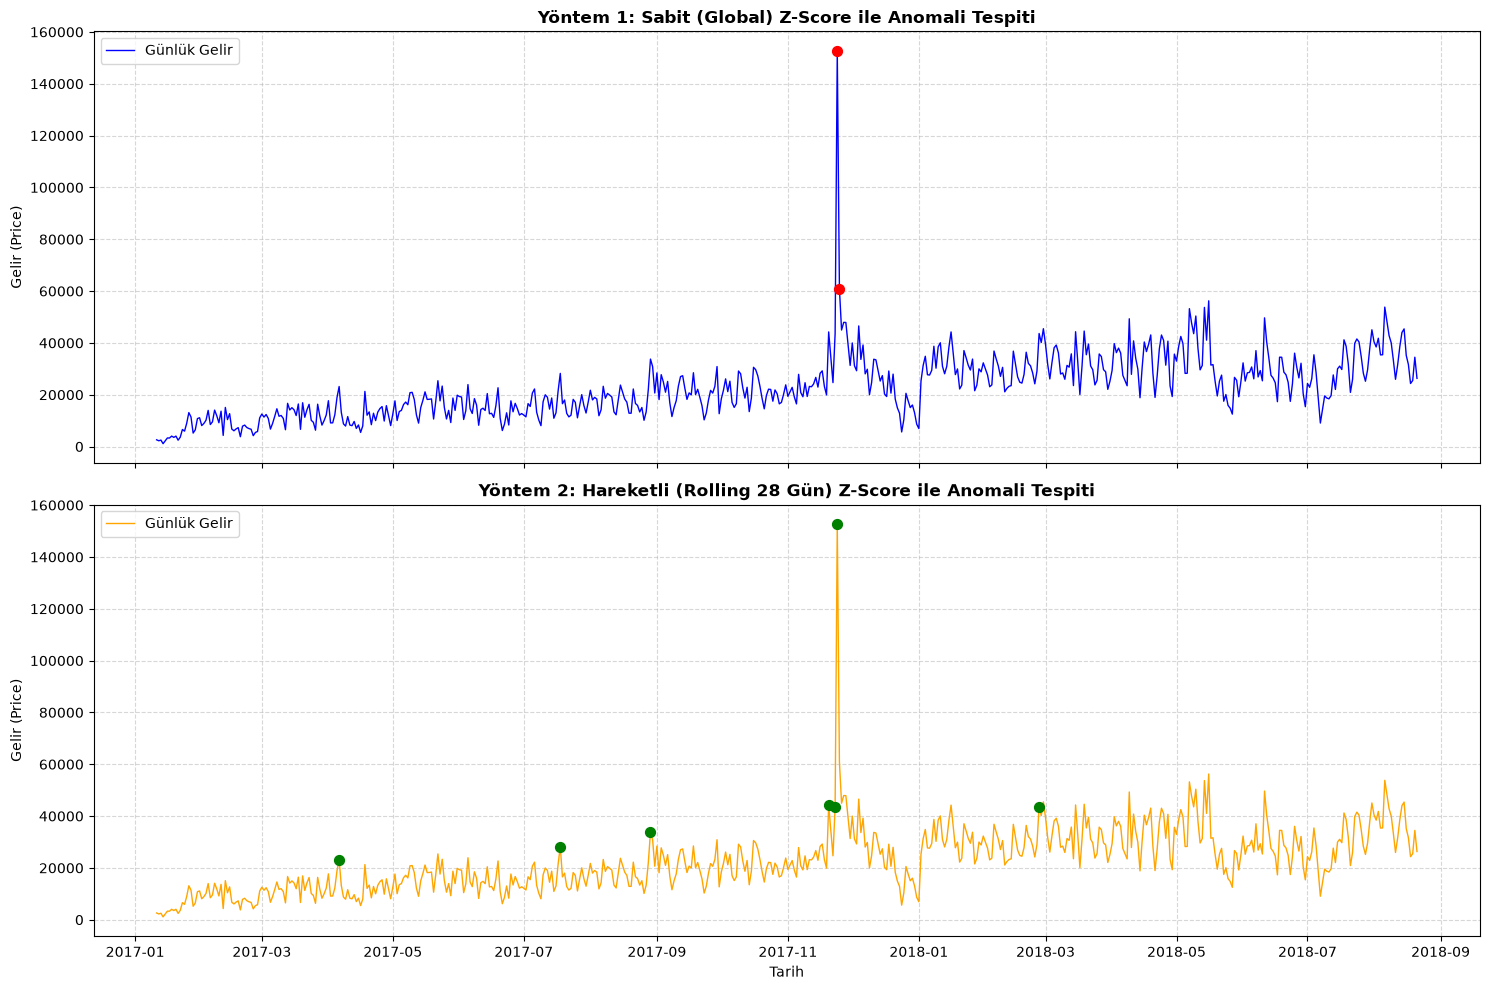

In [15]:
fig, (ax1, ax2) = plt.subplots(nrows = 2, ncols = 1, figsize = (15, 10), sharex = True)

# --- ÜST GRAFİK: GLOBAL Z-SCORE ---
ax1.plot(data['order_purchase_timestamp'], data['price'], color='blue', linewidth=1, label='Günlük Gelir')
# Buraya global anomalileri içeren scatter kodunu ekle (kırmızı noktalar)
# Örn: ax1.scatter(anomalies_global['tarih'], anomalies_global['price'], color='red', zorder=5)
ax1.set_title('Yöntem 1: Sabit (Global) Z-Score ile Anomali Tespiti', fontsize=12, fontweight='bold')
ax1.set_ylabel('Gelir (Price)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

ax1.scatter(
    anomalies['order_purchase_timestamp'],
    anomalies['price'],
    color = "red",
    s = 50, 
    marker = "o",
    zorder = 5,
    label = 'Tespit edilen anomaliler - Sabit Z-Skor Yöntemiyle'
)

# --- ALT GRAFİK: ROLLING Z-SCORE ---
ax2.plot(data['order_purchase_timestamp'], data['price'], color='orange', linewidth=1, label='Günlük Gelir')
ax2.set_title('Yöntem 2: Hareketli (Rolling 28 Gün) Z-Score ile Anomali Tespiti', fontsize=12, fontweight='bold')
ax2.set_xlabel('Tarih')
ax2.set_ylabel('Gelir (Price)')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

ax2.scatter(
    anomalies_rolling['order_purchase_timestamp'],
    anomalies_rolling['price'],
    color = "green",
    s = 50, 
    marker = "o",
    zorder = 5,
    label = 'Tespit edilen anomaliler - Hareketli Z-Skor Yöntemiyle' 
)

plt.tight_layout() # grafiklerin üst üste binmesini engeller ve düzgün bir görüntü oluşturur. 
plt.show() # Grafiği ekrana basalım

Her iki grafiği de alt alta koyup incelediğimizde, 24 Kasımdan sonraki 28 günde standart sapma ve ortalama büyüdüğü için sistem anomaliyi yakalayamayabilir. Çünkü Black Friday'in yarattığı aşırı yüksek standart sapma, sonraki 28 gün boyunca tüm gerçek düşüş anomalilerini yuttu ve sistemi kör etti.


### Kanıt

- 25 Kasım (60 bin): Üstteki grafikte kırmızı, alttakinde işaretsiz. Rolling yöntem Black Friday'i yakaladı, ama ertesi gün referans penceresine giren 152 bin std'yi o kadar şişirdi ki bir sonraki anomali anında kayboldu.

- Aralık 2017 sonu: Gelir yaklaşık 30 binden 6 bine çakılıyor ve hiç işaret yok. Bu, tarif ettiğin "kör dönem"in ta kendisi.


### Sıradaki teknik: Robust z-score (median + MAD)

Sorunun kökü şu: ortalama ve std, tek bir uç değere çok duyarlı. Median ise duyarlı değil. 28 günün birinde 152 bin olsa da median neredeyse hiç kıpırdamaz.

Formül:

- MAD     = median(|x − median(x)|)
- robust_z = 0.6745 × (bugün − median) / MAD
- MAD, std'nin robust karşılığı: "tipik bir gün medianın ne kadar uzağında?"
0.6745 sabiti robust z'yi normal z ile aynı ölçeğe getirir. Böylece eşik olarak yine 3 kullanabilirsin.


In [16]:
data['rolling_median'] = kaydirilmis_gelir.rolling(window=pencere_boyutu).median()

In [17]:
import numpy as np

# MAD formülü: median( |x - median(x)| )
data['rolling_mad'] = kaydirilmis_gelir.rolling(window=pencere_boyutu).apply(
    lambda x: np.median(np.abs(x - np.median(x)))
)

In [18]:
data['robust_z_score'] = 0.6745 * (data['price'] - data['rolling_median']) / data['rolling_mad']

In [19]:
anomalies_robust = data[data['robust_z_score'].abs() > threshold]

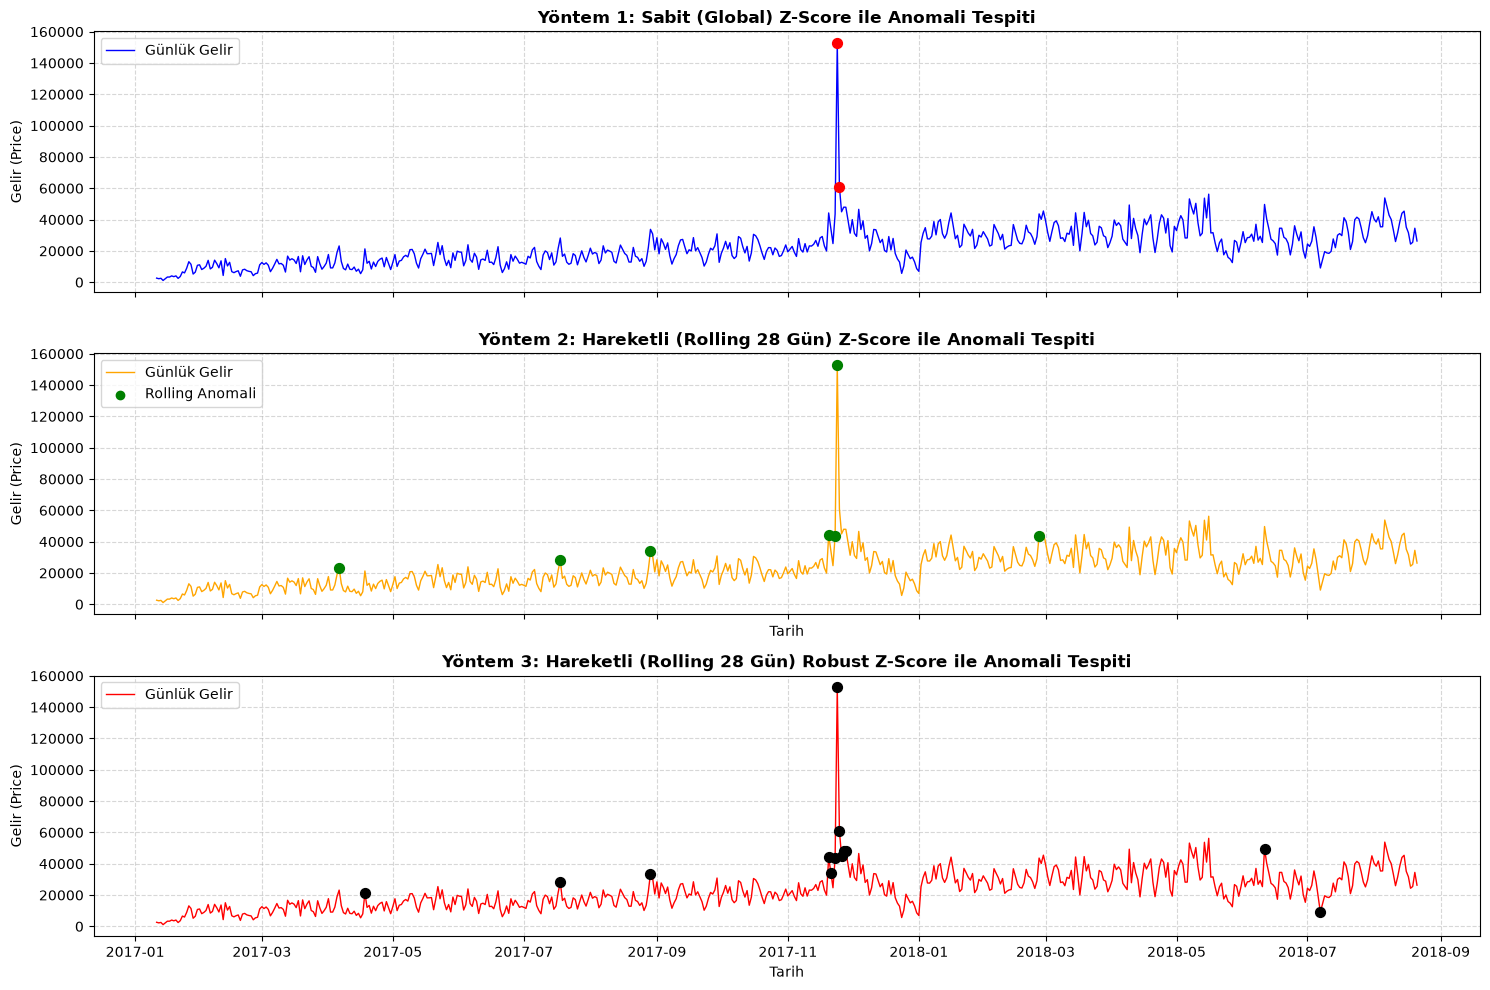

In [20]:
fig, (ax1, ax2, ax3) = plt.subplots(nrows = 3, ncols = 1, figsize = (15, 10), sharex = True)

# --- ÜST GRAFİK: GLOBAL Z-SCORE ---
ax1.plot(data['order_purchase_timestamp'], data['price'], color='blue', linewidth=1, label='Günlük Gelir')
# Buraya global anomalileri içeren scatter kodunu ekle (kırmızı noktalar)
# Örn: ax1.scatter(anomalies_global['tarih'], anomalies_global['price'], color='red', zorder=5)
ax1.set_title('Yöntem 1: Sabit (Global) Z-Score ile Anomali Tespiti', fontsize=12, fontweight='bold')
ax1.set_ylabel('Gelir (Price)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

ax1.scatter(
    anomalies['order_purchase_timestamp'],
    anomalies['price'],
    color = "red",
    s = 50, 
    marker = "o",
    zorder = 5,
    label = 'Tespit edilen anomaliler - Sabit Z-Skor Yöntemiyle'
)

# --- ALT GRAFİK: ROLLING Z-SCORE ---
ax2.plot(data['order_purchase_timestamp'], data['price'], color='orange', linewidth=1, label='Günlük Gelir')
# Buraya senin az önce filtrelediğin anomalies_rolling tablosunu scatter olarak ekle (yeşil noktalar)
ax2.scatter(anomalies_rolling['order_purchase_timestamp'], anomalies_rolling['price'], color='green', zorder=5, label='Rolling Anomali')
ax2.set_title('Yöntem 2: Hareketli (Rolling 28 Gün) Z-Score ile Anomali Tespiti', fontsize=12, fontweight='bold')
ax2.set_xlabel('Tarih')
ax2.set_ylabel('Gelir (Price)')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

ax2.scatter(
    anomalies_rolling['order_purchase_timestamp'],
    anomalies_rolling['price'],
    color = "green",
    s = 50, 
    marker = "o",
    zorder = 5,
    label = 'Tespit edilen anomaliler - Hareketli Z-Skor Yöntemiyle' 
)

# --- 3. GRAFİK: Robust ROLLING Z-SCORE ---
ax3.plot(data['order_purchase_timestamp'], data['price'], color='red', linewidth=1, label='Günlük Gelir')

ax3.set_title('Yöntem 3: Hareketli (Rolling 28 Gün) Robust Z-Score ile Anomali Tespiti', fontsize=12, fontweight='bold')
ax3.set_xlabel('Tarih')
ax3.set_ylabel('Gelir (Price)')
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper left')

ax3.scatter(
    anomalies_robust['order_purchase_timestamp'],
    anomalies_robust['price'],
    color = "black",
    s = 50, 
    marker = "o",
    zorder = 5,
    label = 'Tespit edilen anomaliler - Robust Z-Skor Yöntemiyle' 
)

plt.tight_layout() # grafiklerin üst üste binmesini engeller ve düzgün bir görüntü oluşturur. 
plt.show() # Grafiği ekrana basalım

## Sonuç

### Ne yaptık?
Aynı günlük gelir serisinde üç yöntemi denedik:

1. **Global z-score:** Her günü tüm seriyle karşılaştırır.
   Seride büyüme trendi olduğu için başarısız oldu: Ocak 2017'de
   gelir yarıya düşse bile z ≈ −1,76 olur ve yakalanmaz.
2. **Rolling z-score (28 gün):** Her günü kendinden önceki 28 günle
   karşılaştırır, böylece trend sorununu çözer. Ama ortalama ve std
   uç değerlere duyarlı. Black Friday sonraki 28 günün std'sini
   şişirir ve 25 Kasım (60 bin) gibi anomaliler gizlenir.
3. **Robust rolling z-score:** Ortalama yerine median, std yerine
   MAD kullanır. Tek bir uç değer referansı bozmaz. 25 Kasım'ı ve
   ilk düşüş anomalisini (Temmuz 2018 başı) yakaladı.

### Karar
Faz 1 dedektörü: **robust rolling z-score** (pencere 28 gün,
eşik 3, `shift(1)` ile bugün kendi referansına dahil edilmeden).

### Tespitlerin değerlendirmesi
- **24–28 Kasım 2017:** Black Friday ve Cyber Monday, gerçek olaylar.
- **Temmuz 2018 başı düşüş:** Dünya Kupası maçlarıyla ilişkili
  olabilir. Hipotez, henüz doğrulanmadı.
- **Diğer tespitler:** Ground truth olmadığı için kesin değil.
  Faz 2'de enjekte edilen anomalilerle ölçülecek.

### Sınırlamalar
1. **Sezonsallık:** Aralık sonu (yılbaşı) düşüşü yakalanmıyor. Bu
   beklenen bir düşüş olabilir. "Olağandışı" ile "beklenmeyen"i
   ayırt etmek için forecast tabanlı bir yöntem gerekir (Faz 2).
2. **Alarm kümelenmesi:** Tek bir olay (Black Friday haftası) art
   arda birden fazla alarm üretiyor. İleride ardışık alarmlar tek
   bir olay altında birleştirilecek.

### Kavramlar
- **Trend:** Serinin zamanla kalıcı olarak yükselmesi ya da düşmesi.
- **Rolling pencere:** Her gün için sadece son N günü referans almak.
- **shift(1):** Bugünü kendi referansından çıkarmak. Anomalinin
  kendini gizlemesini ve geleceğe bakmayı (leakage) önler.
- **Median / MAD:** Ortalama ve std'nin uç değerlerden
  etkilenmeyen karşılıkları.
- **Ground truth:** Hangi günlerin gerçekten anomali olduğunun
  bilinen listesi.